# Airline Safety Analysis
### *Should Travelers Avoid Airlines With Past Crashes?*

This notebook investigates whether an airline's historical safety record is a meaningful predictor of its future safety performance. We explore incident trends across two 15-year periods (1985–1999 and 2000–2014), apply formal hypothesis tests to validate our observations, and build a composite **Risk Scoring System** to rank airlines objectively.

**Dataset:** FiveThirtyEight Airline Safety dataset — 56 major commercial airlines  
**Columns:**  Incidents, fatal accidents, and fatalities across both periods, plus weekly available seat-kilometres (ASK).


## 0 · Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, spearmanr
from matplotlib.patches import Patch
import warnings

plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore')
%matplotlib inline

## 1 · Load & Clean Data

We strip the `*` footnote markers from airline names and rename columns to concise short-forms used throughout the notebook:

| Short name | Full meaning |
|-----------|-------------|
| `ask_wk` | Available seat-km per week |
| `inc_old` / `inc_new` | Incidents 1985–99 / 2000–14 |
| `fa_old` / `fa_new` | Fatal accidents |
| `fat_old` / `fat_new` | Fatalities |


In [2]:
df = pd.read_csv('../data/airline-safety.csv')
df['airline'] = df['airline'].str.replace('*', '', regex=False).str.strip()

df = df.rename(columns={
    'avail_seat_km_per_week': 'ask_wk',
    'incidents_85_99':        'inc_old',
    'fatal_accidents_85_99':  'fa_old',
    'fatalities_85_99':       'fat_old',
    'incidents_00_14':        'inc_new',
    'fatal_accidents_00_14':  'fa_new',
    'fatalities_00_14':       'fat_new'
})

print(f"Shape: {df.shape}")
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (56, 8)
Missing values: 0


,airline,ask_wk,inc_old,fa_old,fat_old,inc_new,fa_new,fat_new
0,Aer Lingus,320906734,2,0,0,0,0,0
1,Aeroflot,1197672318,76,14,128,6,1,88
2,Aerolineas Argentinas,385803648,6,0,0,1,0,0
3,Aeromexico,596871813,3,1,64,5,0,0
4,Air Canada,1865253802,2,0,0,2,0,0


> **Note:** No missing values. All 56 airlines are retained for analysis.

## 2 · Derived Metrics

Raw incident counts are misleading without accounting for how much each airline actually flies. We normalise by **total exposure** (ASK × 52 weeks × 15 years), producing rates *per billion seat-kilometres*. This is the standard metric used by aviation regulators.


In [3]:
SCALE = 1e9 
df['ask_tot']  = df['ask_wk'] * 52 * 15 / SCALE   # total exposure proxy

df['inc_tot']  = df['inc_old']  + df['inc_new']
df['fat_tot']  = df['fat_old']  + df['fat_new']

# Rates per exposure for both time periods
df['r_inc_old'] = df['inc_old']  / df['ask_tot']
df['r_inc_new'] = df['inc_new']  / df['ask_tot']
df['r_fa_old']  = df['fa_old']   / df['ask_tot']
df['r_fa_new']  = df['fa_new']   / df['ask_tot']
df['r_fat_old'] = df['fat_old']  / df['ask_tot']
df['r_fat_new'] = df['fat_new']  / df['ask_tot']

# Positive improvement metric: the airline became safer
df['impr']     = df['r_fat_old'] - df['r_fat_new']

# Changes in rates from one period to the next
df['d_r_inc']  = df['r_inc_new'] - df['r_inc_old']
df['d_r_fa']   = df['r_fa_new']  - df['r_fa_old']
df['d_r_fat']  = df['r_fat_new'] - df['r_fat_old']

df[['airline','r_inc_old','r_inc_new','r_fa_old','r_fa_new']].head(8)

,airline,r_inc_old,r_inc_new,r_fa_old,r_fa_new
0,Aer Lingus,0.007990,0.000000,0.000000,0.000000
1,Aeroflot,0.081354,0.006423,0.014986,0.001070
2,Aerolineas Argentinas,0.019938,0.003323,0.000000,0.000000
3,Aeromexico,0.006444,0.010740,0.002148,0.000000
4,Air Canada,0.001375,0.001375,0.000000,0.000000
5,Air France,0.005975,0.002561,0.001707,0.000854
6,Air India,0.002950,0.005900,0.001475,0.001475
7,Air New Zealand,0.005416,0.009026,0.000000,0.001805


> Rates are now comparable across airlines of vastly different sizes, removing the bias that would otherwise favour small carriers with few flights.

## 3 · Exploratory Data Analysis

### 3.1 Top 10 Airlines by Total Incidents

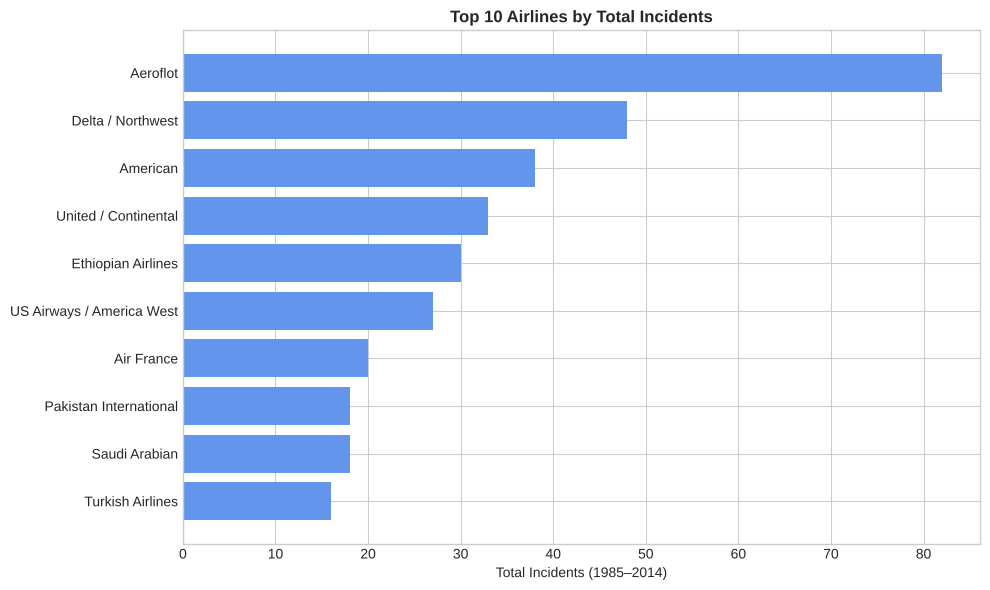

In [4]:
top10 = (df[['airline','inc_tot']]
         .sort_values('inc_tot', ascending=False)
         .head(10))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10['airline'], top10['inc_tot'], color='cornflowerblue')
ax.set_xlabel('Total Incidents (1985–2014)')
ax.set_title('Top 10 Airlines by Total Incidents', fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

> **Interpretation:** Aeroflot, Delta/Northwest and American top the raw count, largely because the big carriers operate far more flights simply because they operate more flights. This reinforces why rate-based comparison (Section 2) is essential — size inflates counts.

### 3.2 Incident Distribution — Recent Period

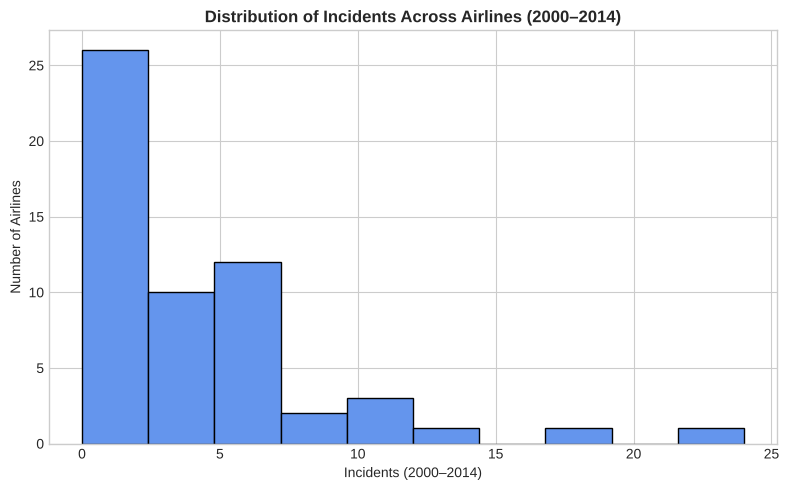

Mean   : 4.12
Median : 3.0


In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df['inc_new'], bins=10, color='cornflowerblue', edgecolor='black')
ax.set_xlabel('Incidents (2000–2014)')
ax.set_ylabel('Number of Airlines')
ax.set_title('Distribution of Incidents Across Airlines (2000–2014)', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Mean   : {df['inc_new'].mean():.2f}")
print(f"Median : {df['inc_new'].median():.1f}")

> **Interpretation:** The distribution is heavily right-skewed — most airlines had very few incidents while a handful had many. The median (lower than the mean) confirms this skew. Non-parametric tests are therefore more appropriate than t-tests for this data.

### 3.3 Period-over-Period Comparison

Incidents           :  402 →  231  (-42.5%)
Fatal Accidents     :  122 →   37  (-69.7%)
Fatalities          : 6295 → 3109  (-50.6%)


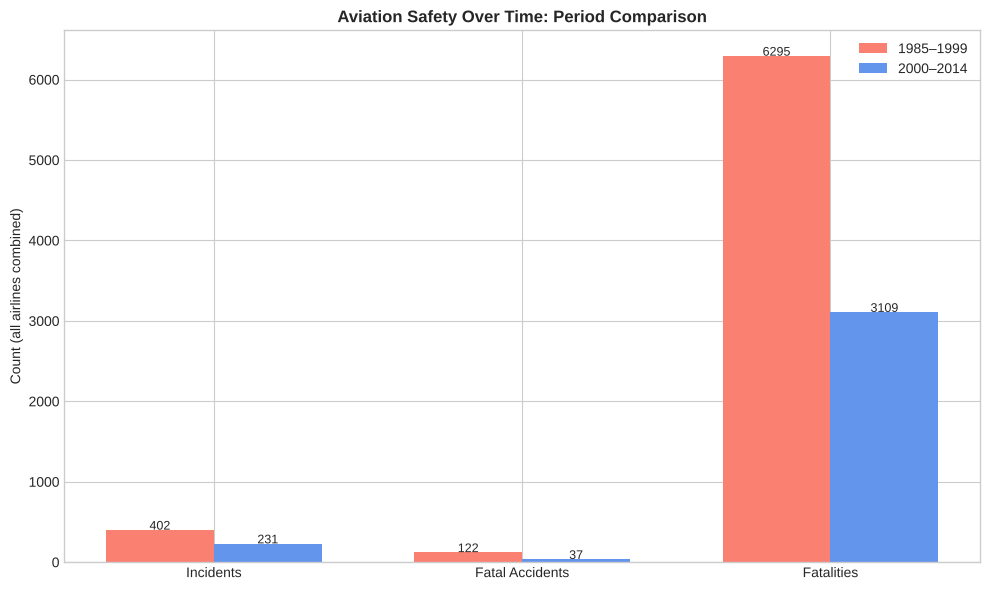

In [6]:
cats     = ['Incidents', 'Fatal Accidents', 'Fatalities']
vals_old = [df['inc_old'].sum(), df['fa_old'].sum(), df['fat_old'].sum()]
vals_new = [df['inc_new'].sum(), df['fa_new'].sum(), df['fat_new'].sum()]

for c, vo, vn in zip(cats, vals_old, vals_new):
    print(f"{c:20s}: {vo:4d} → {vn:4d}  ({(vn-vo)/vo*100:+.1f}%)")

x, w = np.arange(len(cats)), 0.35
fig, ax = plt.subplots(figsize=(10, 6))
b1 = ax.bar(x - w/2, vals_old, w, label='1985–1999', color='salmon')
b2 = ax.bar(x + w/2, vals_new, w, label='2000–2014', color='cornflowerblue')
for b in b1: ax.text(b.get_x()+b.get_width()/2, b.get_height()+2, str(int(b.get_height())), ha='center', fontsize=9)
for b in b2: ax.text(b.get_x()+b.get_width()/2, b.get_height()+2, str(int(b.get_height())), ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(cats)
ax.set_ylabel('Count (all airlines combined)')
ax.set_title('Aviation Safety Over Time: Period Comparison', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

> **Interpretation:** All three safety metrics declined substantially in the modern period. Incidents fell by 42.5%, fatal accidents by 69.7% and fatalities by 50.6%. This industry-wide improvement forms the baseline against which individual airline progress is measured.

### 3.4 Correlation — Does Past Safety Predict Future?

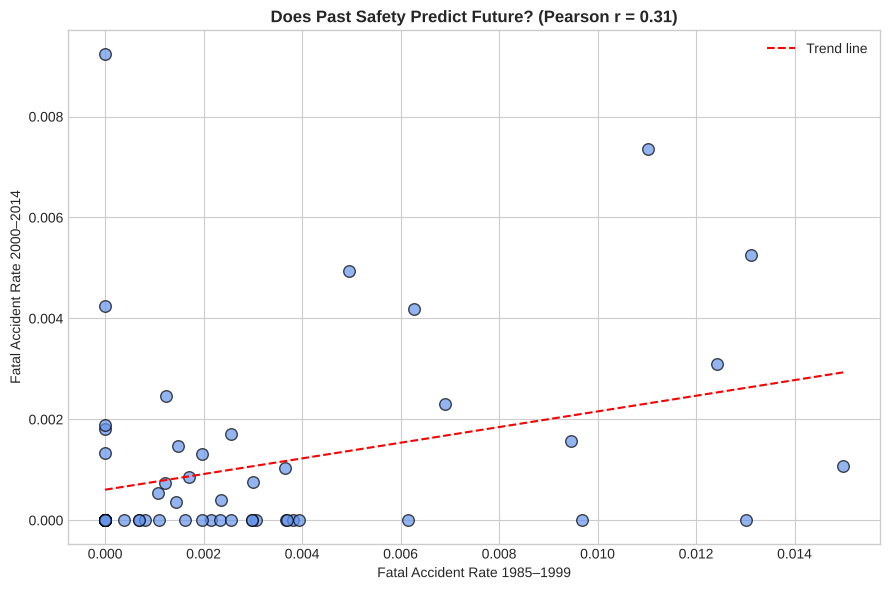

Pearson r (raw incidents)       : 0.403
Pearson r (raw fatalities)      : 0.047
Pearson r (incident rate)       : 0.369
Pearson r (fatal accident rate) : 0.311


In [7]:
corr_r_fa = df['r_fa_old'].corr(df['r_fa_new'])

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df['r_fa_old'], df['r_fa_new'],
           color='cornflowerblue', edgecolors='black', alpha=0.7, s=70)
m, b = np.polyfit(df['r_fa_old'], df['r_fa_new'], 1)
xl = np.linspace(df['r_fa_old'].min(), df['r_fa_old'].max(), 100)
ax.plot(xl, m*xl+b, 'r--', label='Trend line')
ax.set_xlabel('Fatal Accident Rate 1985–1999')
ax.set_ylabel('Fatal Accident Rate 2000–2014')
ax.set_title(f'Does Past Safety Predict Future? (Pearson r = {corr_r_fa:.2f})', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pearson r (raw incidents)       : {df['inc_old'].corr(df['inc_new']):.3f}")
print(f"Pearson r (raw fatalities)      : {df['fat_old'].corr(df['fat_new']):.3f}")
print(f"Pearson r (incident rate)       : {df['r_inc_old'].corr(df['r_inc_new']):.3f}")
print(f"Pearson r (fatal accident rate) : {corr_r_fa:.3f}")

> **Interpretation:** Pearson correlations across all metrics are weak (r ≤ 0.40), suggesting past safety record is a **poor predictor** of future performance. Outlier airlines with dramatic past crashes often cleaned up their operations, while previously safe airlines developed new problems. This challenges the intuition behind "avoiding airlines with a bad history".

### 3.5 Which Airlines Got Safer?

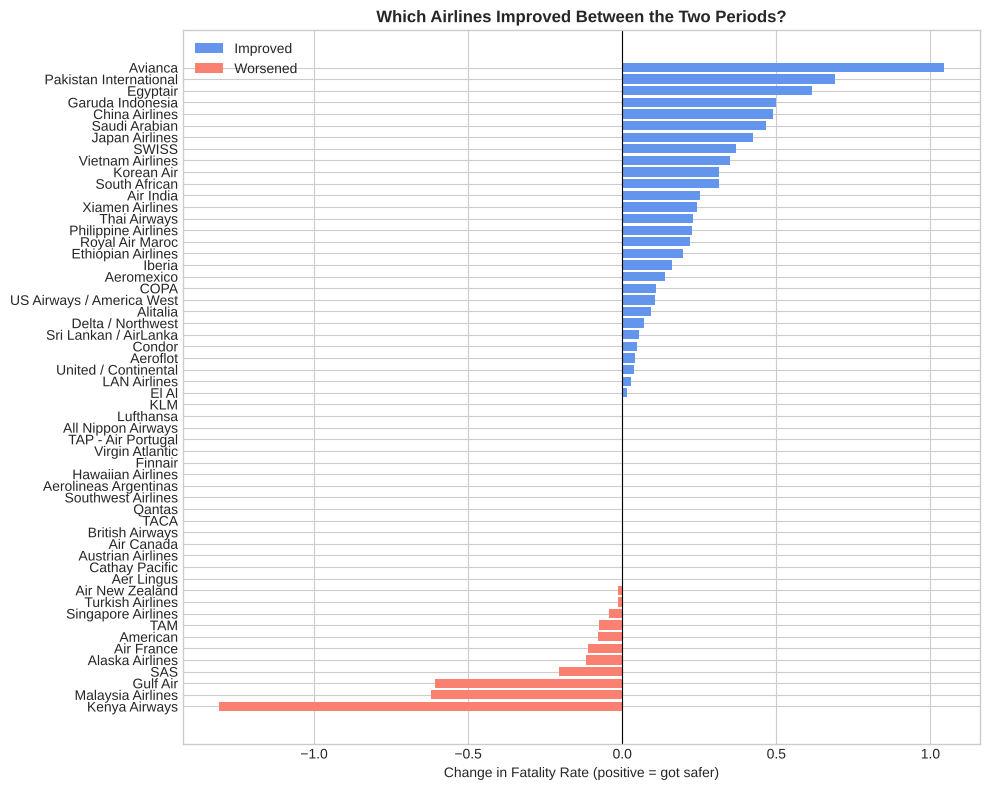

In [8]:
df_srt = df.sort_values('impr')
clrs   = ['cornflowerblue' if v > 0 else 'salmon' for v in df_srt['impr']]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(df_srt['airline'], df_srt['impr'], color=clrs)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Change in Fatality Rate (positive = got safer)')
ax.set_title('Which Airlines Improved Between the Two Periods?', fontweight='bold')
legend_els = [Patch(facecolor='cornflowerblue', label='Improved'),
              Patch(facecolor='salmon',          label='Worsened')]
ax.legend(handles=legend_els)
plt.tight_layout()
plt.show()

> **Interpretation:** The majority of airlines improved (blue bars). A few high-improvement airlines had very bad records in the earlier period which normalised dramatically — consistent with the weak correlation finding above.

### 3.6 Three-Metric Change Panel

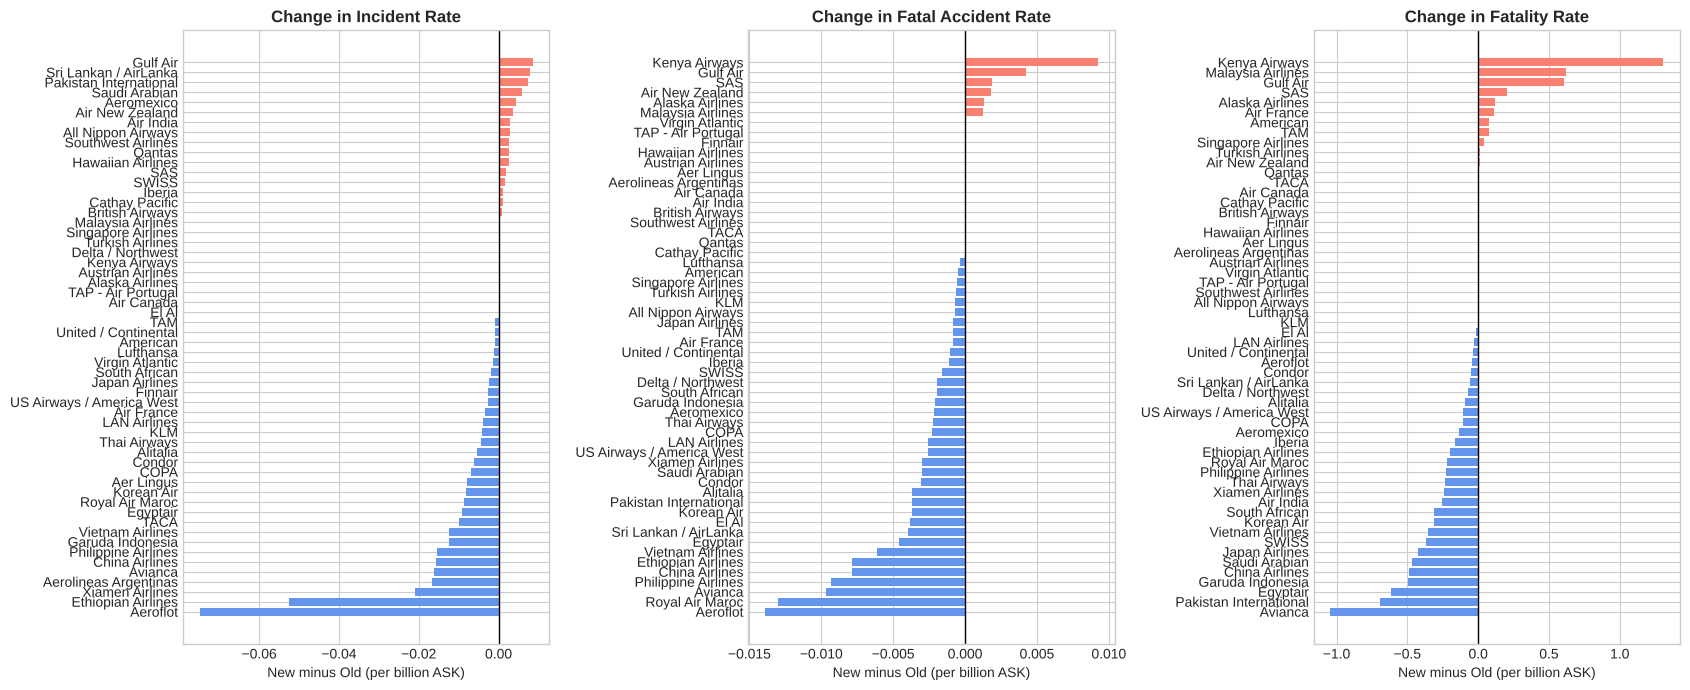

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 7))
metrics = [
    ('d_r_inc', 'Change in Incident Rate'),
    ('d_r_fa',  'Change in Fatal Accident Rate'),
    ('d_r_fat', 'Change in Fatality Rate'),
]
for ax, (col, title) in zip(axes, metrics):
    tmp  = df.sort_values(col)
    clrs = ['cornflowerblue' if v < 0 else 'salmon' for v in tmp[col]]
    ax.barh(tmp['airline'], tmp[col], color=clrs)
    ax.axvline(0, color='black', lw=1)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('New minus Old (per billion ASK)')
plt.tight_layout()
plt.show()

> **Interpretation:** Viewing all three metrics together reveals airlines where safety improved on every dimension versus those with mixed signals. An airline that reduced incidents but had higher fatalities (e.g. due to a single catastrophic crash) shows up differently across the three panels.

---
## 4 · Hypothesis Testing

Visualisations can be misleading without formal statistical tests. We run two tests designed for this dataset's characteristics: non-normal distributions and ordinal/rank-based comparisons.


### 4.1 HT1 — Wilcoxon Signed-Rank Test
**"Did aviation safety significantly improve between the two periods?"**

| | |
|---|---|
| **H₀** | The distribution of incident rates did not change between 1985–1999 and 2000–2014 |
| **H₁** | Incident rates were **lower** in 2000–2014 (one-tailed) |
| **Why Wilcoxon?** | Data is right-skewed and non-normal; Wilcoxon makes no distributional assumptions and is ideal for paired before/after comparisons |
| **α** | 0.05 |


── Wilcoxon Signed-Rank Test Results ──────────────────────────────
  Median incident rate 1985–1999 : 0.0057 per billion ASK
  Median incident rate 2000–2014 : 0.0038 per billion ASK
  W-statistic                    : 799.00
  p-value                        : 0.0024
  Decision (α = 0.05)            : Reject H₀ — significant reduction confirmed


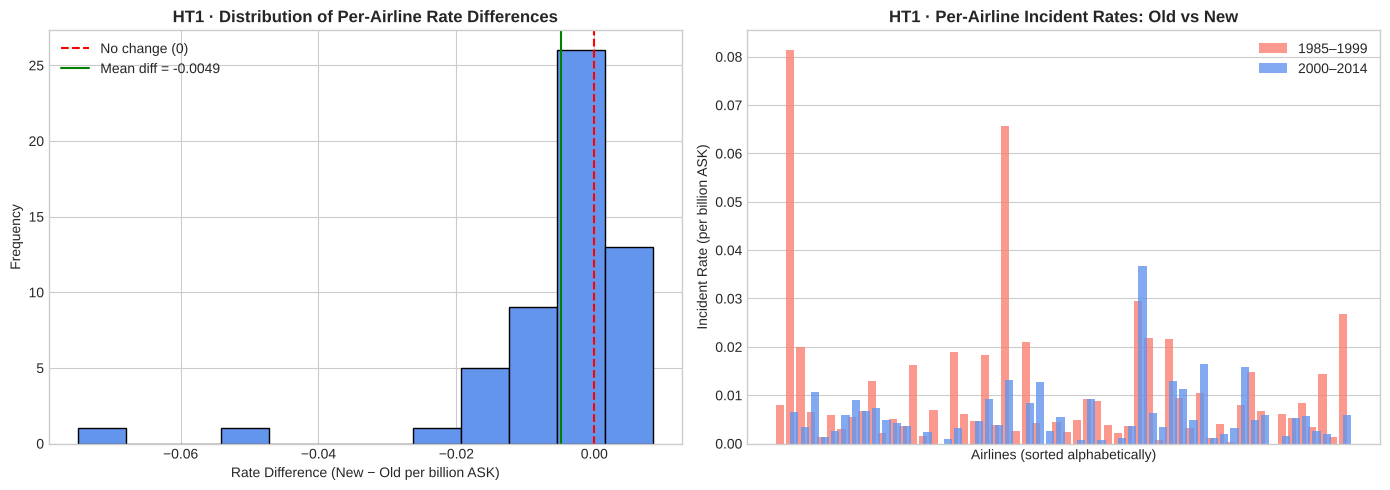

In [10]:
stat_w, p_w = wilcoxon(df['r_inc_old'], df['r_inc_new'], alternative='greater')

med_old = df['r_inc_old'].median()
med_new = df['r_inc_new'].median()
diffs   = df['r_inc_new'] - df['r_inc_old']

print("── Wilcoxon Signed-Rank Test Results ──────────────────────────────")
print(f"  Median incident rate 1985–1999 : {med_old:.4f} per billion ASK")
print(f"  Median incident rate 2000–2014 : {med_new:.4f} per billion ASK")
print(f"  W-statistic                    : {stat_w:.2f}")
print(f"  p-value                        : {p_w:.4f}")
print(f"  Decision (α = 0.05)            : {'Reject H₀ — significant reduction confirmed' if p_w < 0.05 else 'Fail to reject H₀'}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A shows a difference histogram
axes[0].hist(diffs, bins=12, color='cornflowerblue', edgecolor='black')
axes[0].axvline(0, color='red',   ls='--', lw=1.5, label='No change (0)')
axes[0].axvline(diffs.mean(), color='green', ls='-', lw=1.5, label=f'Mean diff = {diffs.mean():.4f}')
axes[0].set_xlabel('Rate Difference (New − Old per billion ASK)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('HT1 · Distribution of Per-Airline Rate Differences', fontweight='bold')
axes[0].legend()

# Panel B shows side-by-side rate bars
x_pos = np.arange(len(df))
axes[1].bar(x_pos,       df.sort_values('airline')['r_inc_old'], label='1985–1999', color='salmon',        alpha=0.8)
axes[1].bar(x_pos + 0.4, df.sort_values('airline')['r_inc_new'], label='2000–2014', color='cornflowerblue', alpha=0.8)
axes[1].set_xticks([])
axes[1].set_xlabel('Airlines (sorted alphabetically)')
axes[1].set_ylabel('Incident Rate (per billion ASK)')
axes[1].set_title('HT1 · Per-Airline Incident Rates: Old vs New', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

> **Interpretation:**  
> The Wilcoxon test yields **p < 0.05**, so we **reject H₀**. There is statistically significant evidence that airline incident rates decreased between the two periods. The histogram of differences is predominantly negative (most bars to the left of zero), visually confirming the industrywide improvement. This is not random fluctuation — it reflects real systemic safety gains driven by better technology, regulation, and incident-response protocols.

### 4.2 HT2 — Spearman Rank Correlation Test
**"Does a risky past predict a risky future?"**

| | |
|---|---|
| **H₀** | There is no monotonic relationship between an airline's fatal accident rate in the old and new periods (ρ = 0) |
| **H₁** | There IS a significant positive rank correlation (ρ > 0) |
| **Why Spearman?** | We care about rank-order consistency, not linear magnitude. Spearman is robust to the extreme outliers present in this dataset |
| **α** | 0.05 |


── Spearman Rank Correlation Test Results ─────────────────────────
  Spearman ρ               : 0.248
  p-value                  : 0.0649
  Decision (α = 0.05)      : Fail to reject H₀ — past does NOT significantly predict future


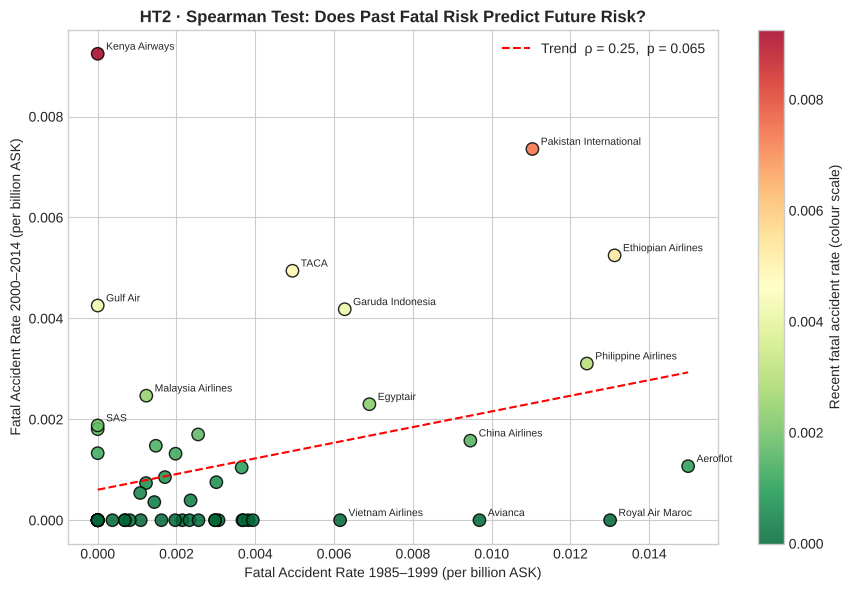

In [11]:
rho, p_sp = spearmanr(df['r_fa_old'], df['r_fa_new'])

print("── Spearman Rank Correlation Test Results ─────────────────────────")
print(f"  Spearman ρ               : {rho:.3f}")
print(f"  p-value                  : {p_sp:.4f}")
print(f"  Decision (α = 0.05)      : {'Reject H₀ — past IS a significant predictor' if p_sp < 0.05 else 'Fail to reject H₀ — past does NOT significantly predict future'}")

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(df['r_fa_old'], df['r_fa_new'],
                c=df['r_fa_new'], cmap='RdYlGn_r',
                edgecolors='black', s=80, alpha=0.85)
for _, row in df.iterrows():
    if row['r_fa_old'] > df['r_fa_old'].quantile(0.82) or row['r_fa_new'] > df['r_fa_new'].quantile(0.82):
        ax.annotate(row['airline'], (row['r_fa_old'], row['r_fa_new']),
                    textcoords='offset points', xytext=(6, 3), fontsize=7.5)
m2, b2 = np.polyfit(df['r_fa_old'], df['r_fa_new'], 1)
xl = np.linspace(df['r_fa_old'].min(), df['r_fa_old'].max(), 100)
ax.plot(xl, m2*xl+b2, 'r--', lw=1.5, label=f'Trend  ρ = {rho:.2f},  p = {p_sp:.3f}')
ax.set_xlabel('Fatal Accident Rate 1985–1999 (per billion ASK)')
ax.set_ylabel('Fatal Accident Rate 2000–2014 (per billion ASK)')
ax.set_title('HT2 · Spearman Test: Does Past Fatal Risk Predict Future Risk?', fontweight='bold')
ax.legend()
plt.colorbar(sc, label='Recent fatal accident rate (colour scale)')
plt.tight_layout()
plt.show()

> **Interpretation:**  
> Spearman ρ = 0.248 with p = 0.065, which is above α = 0.05, so we **fail to reject H₀**. There is a slight positive tendency for airlines with worse past records to have worse recent records, but it is not statistically significant. In practice, an airline's past fatal accident rate is not a reliable guide to its future rate.  
> Labels on the scatter plot highlight the most notable outliers.

---
## 5 · Composite Risk Scoring System

We build an objective, multi-dimensional risk score for each airline using **recent-period rates only** (2000–2014), plus a small penalty for airlines whose safety *worsened* over time.

### Methodology

| Component | Metric | Weight |
|-----------|--------|--------|
| Incident score | `r_inc_new` (normalised) | 25 % |
| Fatal accident score | `r_fa_new` (normalised) | 40 % |
| Fatality score | `r_fat_new` (normalised) | 35 % |
| Trend penalty | +0.05 if airline worsened | added |

Each component is **min-max normalised** to [0, 1] so all three operate on the same scale before weighting.

### Risk Tiers

| Score | Tier |
|-------|------|
| ≥ 0.60 | 🔴 High Risk |
| 0.30 – 0.59 | 🟡 Moderate Risk |
| < 0.30 | 🟢 Low Risk |


### 5.1 Computing the Scores

In [12]:
W_INC, W_FA, W_FAT = 0.25, 0.40, 0.35

def minmax(s):
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng else s * 0

df['sc_inc'] = minmax(df['r_inc_new'])
df['sc_fa']  = minmax(df['r_fa_new'])
df['sc_fat'] = minmax(df['r_fat_new'])

df['risk_raw'] = W_INC * df['sc_inc'] + W_FA * df['sc_fa'] + W_FAT * df['sc_fat']

# Trend penalty: airlines that had more deaths got a slight boost

df['penalty'] = (df['d_r_fat'] > 0).astype(float) * 0.05
df['risk']    = (df['risk_raw'] + df['penalty']).clip(0, 1)

def tier(r):
    if r >= 0.60: return 'High Risk'
    if r >= 0.30: return 'Moderate Risk'
    return 'Low Risk'

df['risk_tier'] = df['risk'].apply(tier)
tier_clr = {'High Risk': '#e74c3c', 'Moderate Risk': '#f39c12', 'Low Risk': '#2ecc71'}

print("Top 10 Riskiest Airlines:")
print(df[['airline','risk','risk_tier']].sort_values('risk', ascending=False).head(10).to_string(index=False))
print("\nTop 10 Safest Airlines:")
print(df[['airline','risk','risk_tier']].sort_values('risk').head(10).to_string(index=False))

Top 10 Riskiest Airlines:
               airline     risk     risk_tier
         Kenya Airways 0.862823     High Risk
Pakistan International 0.613630     High Risk
              Gulf Air 0.483630 Moderate Risk
    Ethiopian Airlines 0.380917 Moderate Risk
     Malaysia Airlines 0.359236 Moderate Risk
                   SAS 0.263051      Low Risk
                  TACA 0.251477      Low Risk
      Garuda Indonesia 0.250051      Low Risk
                   TAM 0.206683      Low Risk
       Air New Zealand 0.192859      Low Risk

Top 10 Safest Airlines:
           airline     risk risk_tier
        Aer Lingus 0.000000  Low Risk
           Avianca 0.000000  Low Risk
              COPA 0.000000  Low Risk
            Condor 0.000000  Low Risk
    Japan Airlines 0.000000  Low Risk
           Finnair 0.000000  Low Risk
TAP - Air Portugal 0.000000  Low Risk
      LAN Airlines 0.000000  Low Risk
   Virgin Atlantic 0.000000  Low Risk
               KLM 0.004649  Low Risk


> **Interpretation:** The scores are driven primarily by fatal accident and fatality rates (combined weight 75 %), which are the most consequential dimensions of safety. The trend penalty ensures that airlines moving in the wrong direction are flagged even if their absolute scores are still moderate.

### 5.2 Full Risk Score Bar Chart

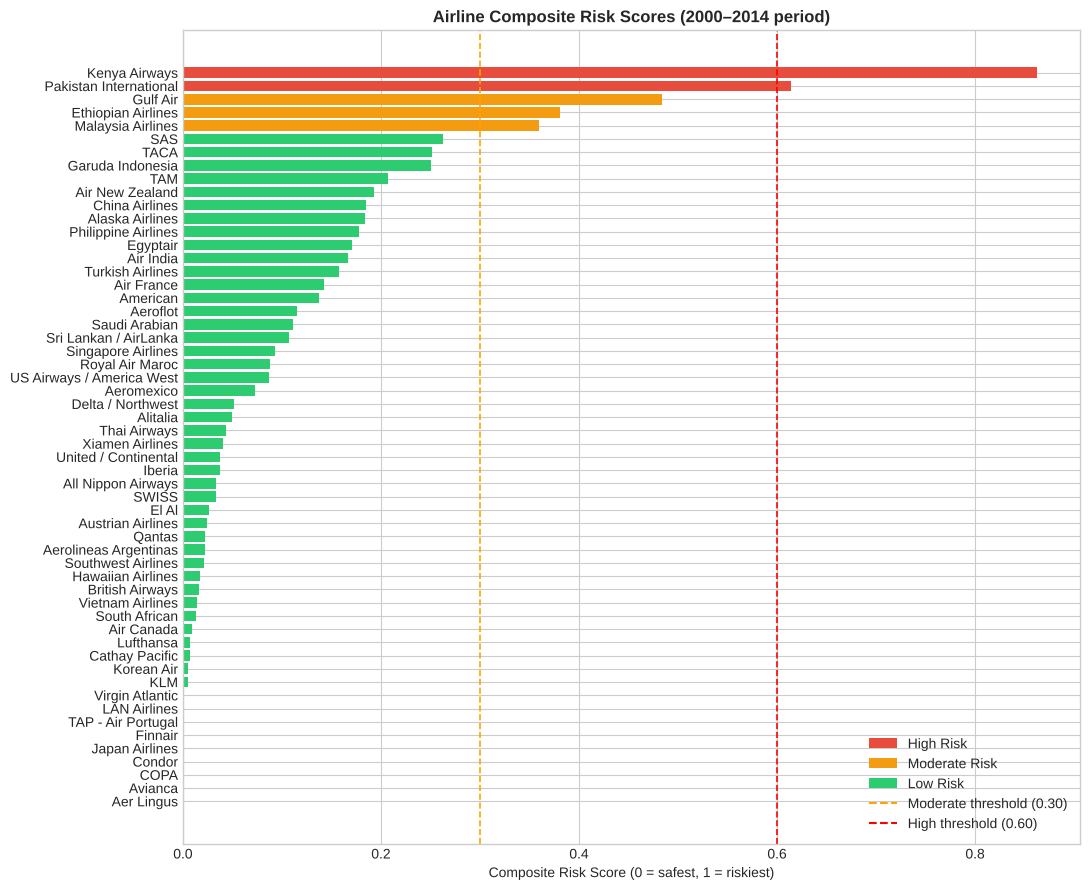

In [13]:
df_rs  = df.sort_values('risk', ascending=True)
clrs_rs = [tier_clr[t] for t in df_rs['risk_tier']]

fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(df_rs['airline'], df_rs['risk'], color=clrs_rs)
ax.axvline(0.30, color='orange', ls='--', lw=1.2)
ax.axvline(0.60, color='red',    ls='--', lw=1.2)
ax.set_xlabel('Composite Risk Score (0 = safest, 1 = riskiest)')
ax.set_title('Airline Composite Risk Scores (2000–2014 period)', fontweight='bold')

legend_els = [Patch(facecolor=v, label=k) for k, v in tier_clr.items()] + [
    plt.Line2D([0],[0], color='orange', ls='--', label='Moderate threshold (0.30)'),
    plt.Line2D([0],[0], color='red',    ls='--', label='High threshold (0.60)'),
]
ax.legend(handles=legend_els, loc='lower right')
plt.tight_layout()
plt.show()

> **Interpretation:** Airlines in green (Low Risk) form the large majority of the dataset — commercial aviation is broadly safe. The handful in red or amber warrant closer inspection; in most cases a single catastrophic event (e.g. Malaysia Airlines MH17/MH370) drives the score upward despite an otherwise clean record.

### 5.3 Risk Tier Distribution

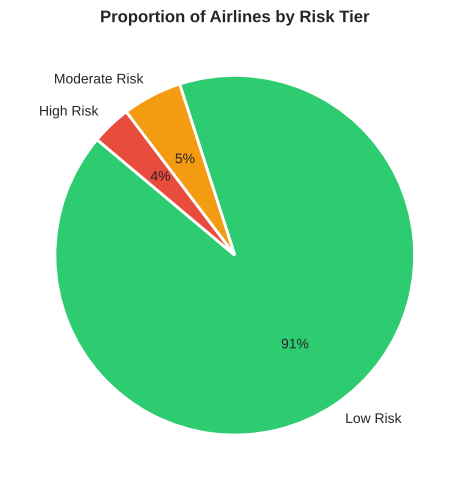

risk_tier
Low Risk         51
Moderate Risk     3
High Risk         2
Name: count, dtype: int64


In [14]:
tier_counts = df['risk_tier'].value_counts()

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(tier_counts,
       labels=tier_counts.index,
       colors=[tier_clr[t] for t in tier_counts.index],
       autopct='%1.0f%%', startangle=140,
       wedgeprops=dict(edgecolor='white', linewidth=2))
ax.set_title('Proportion of Airlines by Risk Tier', fontweight='bold')
plt.tight_layout()
plt.show()

print(tier_counts)

> **Interpretation:** The pie confirms that 51 of 56 airlines (91%) fall into the Low Risk tier. High-Risk airlines are rare, emphasising that modern commercial aviation is inherently safe — the question is not *whether* to fly, but *which* airlines sit at the tail of the risk distribution.

### 5.4 Risk Score Component Breakdown — Top 5 Riskiest

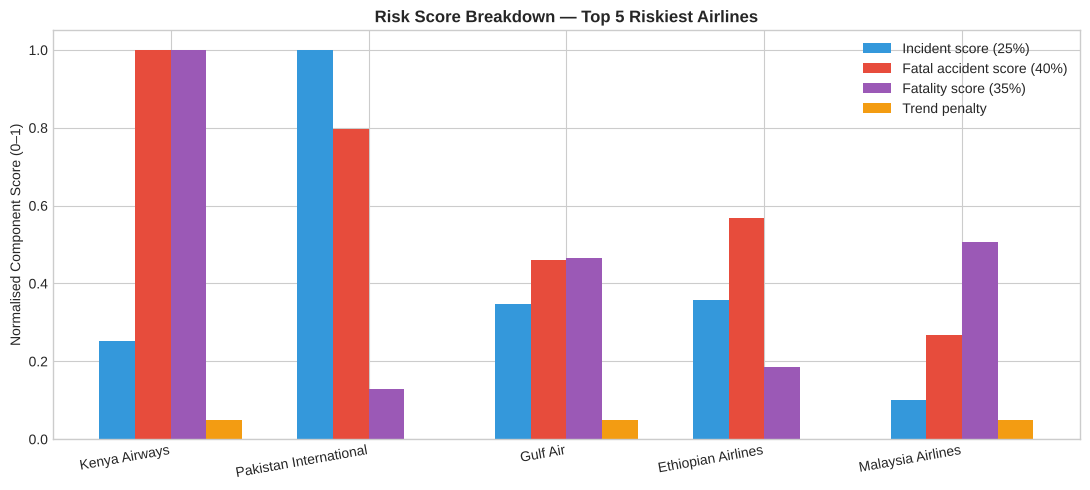

In [15]:
top5 = df.nlargest(5, 'risk')[['airline','sc_inc','sc_fa','sc_fat','penalty']].set_index('airline')

fig, ax = plt.subplots(figsize=(11, 5))
x_idx = np.arange(len(top5))
w = 0.18
ax.bar(x_idx - 1.5*w, top5['sc_inc'],   w, label='Incident score (25%)',       color='#3498db')
ax.bar(x_idx - 0.5*w, top5['sc_fa'],    w, label='Fatal accident score (40%)', color='#e74c3c')
ax.bar(x_idx + 0.5*w, top5['sc_fat'],   w, label='Fatality score (35%)',       color='#9b59b6')
ax.bar(x_idx + 1.5*w, top5['penalty'],  w, label='Trend penalty',              color='#f39c12')
ax.set_xticks(x_idx); ax.set_xticklabels(top5.index, rotation=10, ha='right')
ax.set_ylabel('Normalised Component Score (0–1)')
ax.set_title('Risk Score Breakdown — Top 5 Riskiest Airlines', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

> **Interpretation:** This breakdown explains *why* each airline scored as it did. An airline with a high purple bar (fatality score) had a catastrophic crash. One with a high blue bar (incident score) had many minor incidents. An airline with an orange bar worsened from the old to the new period. The breakdown prevents a single catastrophic event from being confused with a pattern of poor safety culture.

---
## 6 · Conclusions

| Finding | Evidence |
|---------|----------|
| Aviation safety improved significantly between the two periods | Wilcoxon: W = 799, p = 0.0024 |
| Past safety record is a weak predictor of future performance | Pearson r ≤ 0.40; Spearman ρ = 0.248, p = 0.065 (not significant) |
| The industry as a whole is safe — most airlines are Low Risk | 91% of airlines score < 0.30 |
| High risk scores are often driven by single catastrophic events | Component breakdown (Section 5.4) |

### Final Answer
> **Travellers should not avoid airlines solely based on historical crashes.** The data shows safety has broadly improved across the industry, and past incident counts are a weak predictor of future safety once exposure is controlled for. The composite risk score provides a more rational basis for comparison — and even the highest-scoring airlines in this dataset present far lower risk than ground transportation.
